# Ruthvik_Nath_Bandari_AI_Threat_Detection

**AI for Cybersecurity, Module 4 Assignment: AI Threat Detection System** · Ruthvik Nath Bandari · Northeastern University

A Random Forest (ensemble) classifier that separates normal network connections from attacks in the NSL-KDD intrusion
dataset, followed by an analysis of which threats it catches best and how that would help a company in 2025.
Runs on Google Colab with *Runtime → Run all* in about two minutes.

## Step 1 · Setup

In [1]:
# Libraries required by the brief
import pandas as pd
import numpy as np

from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import train_test_split

from sklearn.metrics import accuracy_score, classification_report

import matplotlib.pyplot as plt

import seaborn as sns

# Extra tools used for evaluation and charts
import json
from pathlib import Path
from IPython.display import Markdown, display
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support

SEED = 42
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", "{:.4f}".format)

## Step 2 · Load the dataset

NSL-KDD (Tavallaee et al., 2009) is a cleaned version of the KDD Cup 1999 intrusion data from the DARPA / MIT Lincoln
Laboratory evaluation. Each row is one network connection with 41 features, a label (`normal` or a specific attack) and a
difficulty score. The file has no header row, so the column names are added here.

In [2]:
# Load a network intrusion dataset
url = "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTrain%2B.txt"

COLUMNS = [
    "duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes", "land", "wrong_fragment", "urgent",
    "hot", "num_failed_logins", "logged_in", "num_compromised", "root_shell", "su_attempted", "num_root",
    "num_file_creations", "num_shells", "num_access_files", "num_outbound_cmds", "is_host_login", "is_guest_login",
    "count", "srv_count", "serror_rate", "srv_serror_rate", "rerror_rate", "srv_rerror_rate", "same_srv_rate",
    "diff_srv_rate", "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count", "dst_host_same_srv_rate",
    "dst_host_diff_srv_rate", "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate", "dst_host_serror_rate",
    "dst_host_srv_serror_rate", "dst_host_rerror_rate", "dst_host_srv_rerror_rate", "label", "difficulty",
]
df = pd.read_csv(url, names=COLUMNS)
print(f"Loaded {len(df):,} connections x {df.shape[1]} columns")
df.head()

Loaded 125,973 connections x 43 columns


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.1700,0.0300,0.1700,0.0000,0.0000,0.0000,0.0500,0.0000,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.0000,0.6000,0.8800,0.0000,0.0000,0.0000,0.0000,0.0000,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.1000,0.0500,0.0000,0.0000,1.0000,1.0000,0.0000,0.0000,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.0000,0.0000,0.0300,0.0400,0.0300,0.0100,0.0000,0.0100,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,normal,21


## Step 3 · Build your AI detective

### 3.1 Explore: what types of network activity are there?

Each specific attack belongs to one of four families: **DoS** (denial of service, flooding a service until it fails),
**Probe** (scanning for targets), **R2L** (remote-to-local, unauthorised access from outside) and **U2R** (user-to-root,
privilege escalation).

family
Normal    67343
DoS       45927
Probe     11656
R2L         995
U2R          52 

Most common specific attacks:
label
neptune      41214
satan         3633
ipsweep       3599
portsweep     2931
smurf         2646
nmap          1493
back           956
teardrop       892


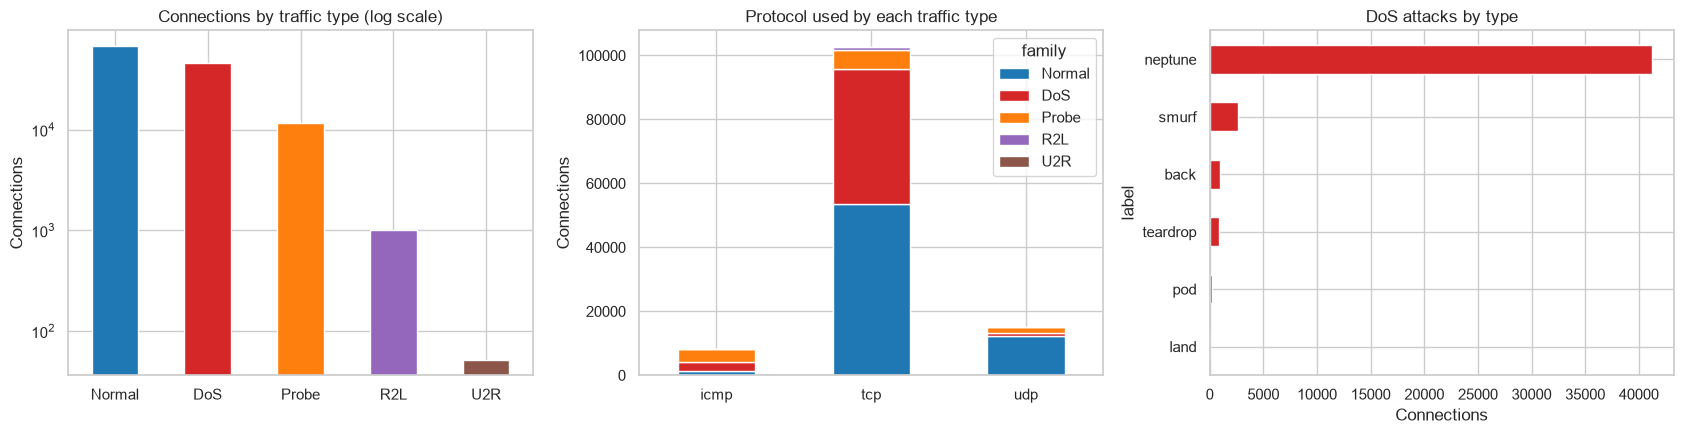

In [3]:
FAMILY = {
    "back": "DoS", "land": "DoS", "neptune": "DoS", "pod": "DoS", "smurf": "DoS", "teardrop": "DoS",
    "apache2": "DoS", "mailbomb": "DoS", "processtable": "DoS", "udpstorm": "DoS",
    "ipsweep": "Probe", "nmap": "Probe", "portsweep": "Probe", "satan": "Probe", "mscan": "Probe", "saint": "Probe",
    "ftp_write": "R2L", "guess_passwd": "R2L", "imap": "R2L", "multihop": "R2L", "phf": "R2L", "spy": "R2L",
    "warezclient": "R2L", "warezmaster": "R2L", "sendmail": "R2L", "named": "R2L", "snmpgetattack": "R2L",
    "snmpguess": "R2L", "xlock": "R2L", "xsnoop": "R2L", "worm": "R2L",
    "buffer_overflow": "U2R", "loadmodule": "U2R", "perl": "U2R", "rootkit": "U2R", "httptunnel": "U2R",
    "ps": "U2R", "sqlattack": "U2R", "xterm": "U2R",
}
df["family"] = df["label"].map(FAMILY).fillna("Normal")
print(df["family"].value_counts().to_string(), "\n")
print("Most common specific attacks:")
print(df.loc[df.label != "normal", "label"].value_counts().head(8).to_string())

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
order = ["Normal", "DoS", "Probe", "R2L", "U2R"]
colors = ["tab:blue", "tab:red", "tab:orange", "tab:purple", "tab:brown"]
df["family"].value_counts().reindex(order).plot.bar(ax=axes[0], color=colors, rot=0, logy=True)
axes[0].set(title="Connections by traffic type (log scale)", ylabel="Connections", xlabel="")
pd.crosstab(df["protocol_type"], df["family"])[order].plot.bar(ax=axes[1], stacked=True, color=colors, rot=0)
axes[1].set(title="Protocol used by each traffic type", ylabel="Connections", xlabel="")
df.loc[df.family == "DoS", "label"].value_counts().head(6)[::-1].plot.barh(ax=axes[2], color="tab:red")
axes[2].set(title="DoS attacks by type", xlabel="Connections")
fig.tight_layout(); fig.savefig(FIG_DIR / "fig1_traffic_types.png", dpi=200); plt.show()

### 3.2 Clean: remove missing or corrupted entries

Checks: missing values, exact duplicate rows, impossible values (negative byte counts or durations), and columns that
never change. The three text columns (`protocol_type`, `service`, `flag`) are one-hot encoded because the Random Forest
needs numbers. The `difficulty` score is metadata about the dataset, not a property of the traffic, so it is dropped.

In [4]:
n_raw = len(df)
missing = int(df.isna().sum().sum())
dupes = int(df.duplicated().sum())
negative = int((df[["duration", "src_bytes", "dst_bytes"]] < 0).any(axis=1).sum())
clean = df.dropna().drop_duplicates()
clean = clean[(clean[["duration", "src_bytes", "dst_bytes"]] >= 0).all(axis=1)]
constant = [c for c in clean.columns if clean[c].nunique() == 1]
print(f"Missing values: {missing} | duplicate rows: {dupes} | negative values: {negative} | constant columns: {constant}")
print(f"Rows kept: {len(clean):,} of {n_raw:,}")

def to_features(frame, columns=None):
    X = pd.get_dummies(frame.drop(columns=["label", "difficulty", "family"] + constant), columns=["protocol_type", "service", "flag"])
    return X if columns is None else X.reindex(columns=columns, fill_value=0)

X = to_features(clean)
y = (clean["label"] != "normal").astype(int)            # 1 = suspicious (any attack), 0 = normal
print(f"Feature matrix: {X.shape[0]:,} rows x {X.shape[1]} features | attacks: {y.mean():.1%}")

Missing values: 0 | duplicate rows: 0 | negative values: 0 | constant columns: ['num_outbound_cmds']
Rows kept: 125,973 of 125,973
Feature matrix: 125,973 rows x 121 features | attacks: 46.5%


### 3.3 Create and train the detector

A **Random Forest** is an ensemble: hundreds of decision trees, each trained on a random sample of connections and
features, vote on every prediction. This is supervised learning, so it learns the attacks it has seen. The data is split
80/20 with stratification, so both parts keep the same mix of normal and attack traffic.

In [5]:
X_train, X_test, y_train, y_test, fam_train, fam_test = train_test_split(
    X, y, clean["family"], test_size=0.2, stratify=y, random_state=SEED)

model = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)
model.fit(X_train, y_train)
print(f"Trained on {len(X_train):,} connections; testing on {len(X_test):,} held-out connections")

Trained on 100,778 connections; testing on 25,195 held-out connections


## Step 4 · Test your system

### 4.1 How accurate is the threat detector?

In [6]:
pred = model.predict(X_test)
proba = model.predict_proba(X_test)[:, 1]
acc = accuracy_score(y_test, pred)
print(f"Accuracy on held-out data: {acc:.4f}\n")
print(classification_report(y_test, pred, target_names=["Normal", "Attack"], digits=4))
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
print(f"False alarms: {fp} of {tn + fp:,} normal connections | missed attacks: {fn} of {tp + fn:,}")

Accuracy on held-out data: 0.9990

              precision    recall  f1-score   support

      Normal     0.9987    0.9995    0.9991     13469
      Attack     0.9994    0.9986    0.9990     11726

    accuracy                         0.9990     25195
   macro avg     0.9991    0.9990    0.9990     25195
weighted avg     0.9990    0.9990    0.9990     25195

False alarms: 7 of 13,469 normal connections | missed attacks: 17 of 11,726


### 4.2 Which threats does it detect best?

Detection rate (recall) for each attack family on the held-out data.

In [7]:
split_rate = (pd.DataFrame({"family": fam_test.values, "caught": pred})
              .query("family != 'Normal'").groupby("family")["caught"].agg(["size", "mean"])
              .rename(columns={"size": "connections", "mean": "detection rate"}).reindex(["DoS", "Probe", "R2L", "U2R"]))
split_rate

,connections,detection rate
family,,
DoS,9105,0.9999
Probe,2389,0.9975
R2L,226,0.9558
U2R,6,1.0000


### 4.3 Reality check: attacks the model has never seen

The held-out split above comes from the same file as the training data, so it contains the same attack types. NSL-KDD
also has an official test file (`KDDTest+`) that includes **17 attack types missing from training**. Scoring it shows how
the detector copes with new threats, which is what a real company faces.

In [8]:
test_url = "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTest%2B.txt"
official = pd.read_csv(test_url, names=COLUMNS)
official["family"] = official["label"].map(FAMILY).fillna("Normal")
X_off = to_features(official, columns=X.columns)
y_off = (official["label"] != "normal").astype(int)
pred_off = model.predict(X_off)
acc_off = accuracy_score(y_off, pred_off)
novel = sorted(set(official.label) - set(df.label))
off = official.assign(caught=pred_off, novel=official.label.isin(novel))
off_rate = (off.query("family != 'Normal'").groupby("family")["caught"].agg(["size", "mean"])
            .rename(columns={"size": "connections", "mean": "detection rate"}).reindex(["DoS", "Probe", "R2L", "U2R"]))
seen_vs_novel = off.query("family != 'Normal'").groupby("novel")["caught"].mean()
fpr_off = ((pred_off == 1) & (y_off == 0)).sum() / (y_off == 0).sum()
print(f"Official test set: {len(official):,} connections, {len(novel)} attack types never seen in training")
print(f"Accuracy: {acc_off:.4f} (held-out split: {acc:.4f}) | false-alarm rate on normal traffic: {fpr_off:.2%}")
print(f"Detection rate on attack types seen in training: {seen_vs_novel[False]:.1%}; on new types: {seen_vs_novel[True]:.1%}")
off_rate

Official test set: 22,544 connections, 17 attack types never seen in training
Accuracy: 0.7673 (held-out split: 0.9990) | false-alarm rate on normal traffic: 2.66%
Detection rate on attack types seen in training: 76.9%; on new types: 23.0%


,connections,detection rate
family,,
DoS,7458,0.7890
Probe,2421,0.7352
R2L,2754,0.0563
U2R,200,0.1350


### 4.4 Visualize the results

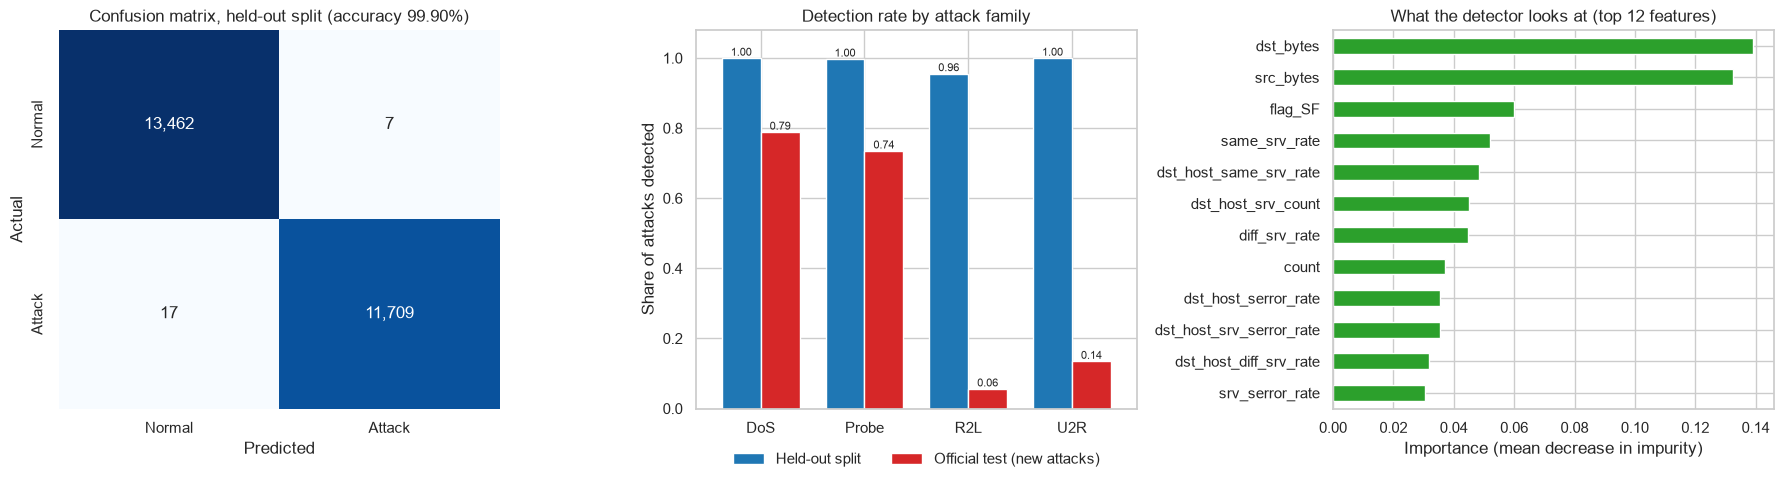

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
cm = confusion_matrix(y_test, pred)
sns.heatmap(cm, annot=np.array([[f"{v:,}" for v in r] for r in cm]), fmt="", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["Normal", "Attack"], yticklabels=["Normal", "Attack"])
axes[0].set(title=f"Confusion matrix, held-out split (accuracy {acc:.2%})", xlabel="Predicted", ylabel="Actual")

comp = pd.DataFrame({"Held-out split": split_rate["detection rate"], "Official test (new attacks)": off_rate["detection rate"]})
comp.plot.bar(ax=axes[1], rot=0, color=["tab:blue", "tab:red"], width=0.75)
axes[1].set(title="Detection rate by attack family", ylabel="Share of attacks detected", ylim=(0, 1.08), xlabel="")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2, frameon=False)
for c in axes[1].containers:
    axes[1].bar_label(c, fmt="%.2f", fontsize=8)

imp = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
imp.head(12)[::-1].plot.barh(ax=axes[2], color="tab:green")
axes[2].set(title="What the detector looks at (top 12 features)", xlabel="Importance (mean decrease in impurity)")
fig.tight_layout(); fig.savefig(FIG_DIR / "fig2_results.png", dpi=200); plt.show()

### 4.5 Top threats: which network activities are most dangerous?

"Dangerous" here combines two things: how common an attack is, and how well it evades the detector. A frequent attack
the model catches is a solved problem; a rarer one it misses is the real risk.

In [10]:
by_type = (off.query("family != 'Normal'").groupby(["label", "family"])
           .agg(connections=("caught", "size"), detection_rate=("caught", "mean"), new_type=("novel", "first"))
           .reset_index())
by_type["missed"] = (by_type["connections"] * (1 - by_type["detection_rate"])).round().astype(int)
top_missed = by_type.sort_values("missed", ascending=False).head(8).reset_index(drop=True)
print("Attack types that slipped through most often on the official test set:")
top_missed

Attack types that slipped through most often on the official test set:


,label,family,connections,detection_rate,new_type,missed
0,guess_passwd,R2L,1231,0.0000,False,1231
1,warezmaster,R2L,944,0.1578,False,795
2,processtable,DoS,685,0.0146,True,675
3,mscan,Probe,996,0.3614,True,636
4,apache2,DoS,737,0.2022,True,588
5,snmpguess,R2L,331,0.0000,True,331
6,mailbomb,DoS,293,0.0000,True,293
7,snmpgetattack,R2L,178,0.0000,True,178


In [11]:
dos = clean[clean.family == "DoS"]; normal = clean[clean.family == "Normal"]
dos_profile = pd.DataFrame({
    "DoS median": dos[["count", "serror_rate", "same_srv_rate", "src_bytes"]].median(),
    "Normal median": normal[["count", "serror_rate", "same_srv_rate", "src_bytes"]].median()})
print("Why DoS is easy to spot: a flood looks very different from normal traffic")
dos_profile

Why DoS is easy to spot: a flood looks very different from normal traffic


,DoS median,Normal median
count,172.0000,4.0000
serror_rate,1.0000,0.0000
same_srv_rate,0.0700,1.0000
src_bytes,0.0000,233.0000


## Step 5 · Professional report

In [12]:
best_family = off_rate["detection rate"].idxmax(); worst_family = off_rate["detection rate"].idxmin()
display(Markdown(f"""
**What accuracy did the AI achieve?** {acc:.2%} on held-out connections from the training file, with only {fp} false
alarms among {tn + fp:,} normal connections. On the harder official test set, which contains {len(novel)} attack types it
never saw, accuracy fell to **{acc_off:.2%}**.

**What types of threats does it detect best?** **{best_family}** attacks: {off_rate.loc[best_family, 'detection rate']:.1%}
detected even on the official test set ({split_rate.loc['DoS', 'detection rate']:.2%} on the held-out split). Floods
are statistically loud: DoS connections have a median of {dos_profile.loc['count', 'DoS median']:.0f} connections to the same
host in two seconds, against {dos_profile.loc['count', 'Normal median']:.0f} for normal traffic. It is weakest on
**{worst_family}** ({off_rate.loc[worst_family, 'detection rate']:.1%}) and on new attack types
({seen_vs_novel[True]:.1%} vs {seen_vs_novel[False]:.1%} for known types), because a supervised model only recognises
what it was trained on.

**How could this help a real company in 2025?** As a fast first filter in a security operations centre, flagging floods
and scans in real time so analysts can focus on the rarer, quieter attacks, paired with anomaly detection for the threats
it has never seen and retrained as new attacks appear.
"""))


**What accuracy did the AI achieve?** 99.90% on held-out connections from the training file, with only 7 false
alarms among 13,469 normal connections. On the harder official test set, which contains 17 attack types it
never saw, accuracy fell to **76.73%**.

**What types of threats does it detect best?** **DoS** attacks: 78.9%
detected even on the official test set (99.99% on the held-out split). Floods
are statistically loud: DoS connections have a median of 172 connections to the same
host in two seconds, against 4 for normal traffic. It is weakest on
**R2L** (5.6%) and on new attack types
(23.0% vs 76.9% for known types), because a supervised model only recognises
what it was trained on.

**How could this help a real company in 2025?** As a fast first filter in a security operations centre, flagging floods
and scans in real time so analysts can focus on the rarer, quieter attacks, paired with anomaly detection for the threats
it has never seen and retrained as new attacks appear.


## Reflection

In Modules 1 and 3, I built anomaly detectors that learned only from normal traffic. This supervised Random Forest is
the opposite: near-perfect on attacks it has seen, and much weaker on ones it has not. The two approaches are
complementary, and the drop on the official test set convinced me that a high accuracy on a random split says little
about a real network. I want to build detection systems that combine both, and that are judged on the threats they miss.

In [13]:
# Machine-readable summary of this run (used to build the slide deck)
SUMMARY = {
    "n_raw": n_raw, "n_clean": int(len(clean)), "dupes": dupes, "missing": missing, "n_features": int(X.shape[1]),
    "family_counts": df["family"].value_counts().to_dict(), "attack_share": float(y.mean()),
    "acc": float(acc), "fp": int(fp), "fn": int(fn), "tp": int(tp), "tn": int(tn),
    "acc_off": float(acc_off), "fpr_off": float(fpr_off), "n_off": int(len(official)), "n_novel": len(novel),
    "split_rate": split_rate["detection rate"].to_dict(), "off_rate": off_rate["detection rate"].to_dict(),
    "seen_rate": float(seen_vs_novel[False]), "novel_rate": float(seen_vs_novel[True]),
    "top_features": imp.head(8).round(4).to_dict(),
    "top_missed": top_missed[["label", "family", "connections", "detection_rate", "missed", "new_type"]].to_dict("records"),
    "dos_profile": dos_profile.to_dict(), "dos_share": float((df.family == "DoS").mean()),
    "dos_types": df.loc[df.family == "DoS", "label"].value_counts().head(5).to_dict(),
}
print(json.dumps(SUMMARY, indent=1, default=lambda o: o.item() if hasattr(o, "item") else str(o)))

{
 "n_raw": 125973,
 "n_clean": 125973,
 "dupes": 0,
 "missing": 0,
 "n_features": 121,
 "family_counts": {
  "Normal": 67343,
  "DoS": 45927,
  "Probe": 11656,
  "R2L": 995,
  "U2R": 52
 },
 "attack_share": 0.4654171925730117,
 "acc": 0.999047430045644,
 "fp": 7,
 "fn": 17,
 "tp": 11709,
 "tn": 13462,
 "acc_off": 0.7673438608942512,
 "fpr_off": 0.026567809700339822,
 "n_off": 22544,
 "n_novel": 17,
 "split_rate": {
  "DoS": 0.999890170236134,
  "Probe": 0.9974884889074926,
  "R2L": 0.9557522123893806,
  "U2R": 1.0
 },
 "off_rate": {
  "DoS": 0.7889514615178332,
  "Probe": 0.7352333746385791,
  "R2L": 0.05628177196804648,
  "U2R": 0.135
 },
 "seen_rate": 0.7690190465705163,
 "novel_rate": 0.2296,
 "top_features": {
  "dst_bytes": 0.1391,
  "src_bytes": 0.1323,
  "flag_SF": 0.0599,
  "same_srv_rate": 0.0521,
  "dst_host_same_srv_rate": 0.0485,
  "dst_host_srv_count": 0.0451,
  "diff_srv_rate": 0.0448,
  "count": 0.0371
 },
 "top_missed": [
  {
   "label": "guess_passwd",
   "family": "R